# Unit 3: Menelaah Data
**Kode unit:** J.62DMI00.005.1 · SKKNI No. 299 Tahun 2020 · Proyek: *Prediksi Arah Harian IHSG*

**Tujuan unit ini:** mengenal isi data: ukuran, tipe, pola, dan hubungan antarvariabel.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

## 1. Membaca data

In [2]:
df = pd.read_csv('../data/raw/market_data.csv', parse_dates=['Date'])
print('Jumlah baris :', len(df))
print('Jumlah kolom :', df.shape[1])
print('Periode      :', df['Date'].min().date(), 's.d.', df['Date'].max().date())
df.head()

Jumlah baris : 4277
Jumlah kolom : 10
Periode      : 2010-01-01 s.d. 2026-05-29


,Date,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate
0,2010-01-01,NaN,NaN,9385.599609,NaN,NaN,NaN,5.134206,6.5,0.11
1,2010-01-04,81.510002,1117.699951,9364.200195,1132.989990,2575.312988,20.040001,5.134206,6.5,0.11
2,2010-01-05,81.769997,1118.099976,9305.200195,1136.520020,2605.175537,19.350000,5.134206,6.5,0.11
3,2010-01-06,83.180000,1135.900024,9218.099609,1137.140015,2603.195557,19.160000,5.134206,6.5,0.11
4,2010-01-07,82.660004,1133.099976,9272.500000,1141.689941,2586.794189,19.059999,5.134206,6.5,0.11


| Kolom | Arti |
|---|---|
| Date | Tanggal (hari kerja) |
| IHSG | Indeks Harga Saham Gabungan |
| SP500 | Indeks saham Amerika |
| VIX | Indeks "ketakutan" pasar global |
| OIL, GOLD | Harga minyak dan emas (USD) |
| USDIDR | Kurs dolar AS terhadap rupiah |
| CPI | Inflasi tahunan Indonesia (%) |
| BI_rate, US_rate | Suku bunga Bank Indonesia dan Amerika (%) |

## 2. Tipe data dan statistik ringkas

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4277 entries, 0 to 4276
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     4277 non-null   datetime64[ns]
 1   OIL      4276 non-null   float64       
 2   GOLD     4276 non-null   float64       
 3   USDIDR   4277 non-null   float64       
 4   SP500    4276 non-null   float64       
 5   IHSG     4276 non-null   float64       
 6   VIX      4276 non-null   float64       
 7   CPI      4277 non-null   float64       
 8   BI_rate  4277 non-null   float64       
 9   US_rate  4277 non-null   float64       
dtypes: datetime64[ns](1), float64(9)
memory usage: 334.3 KB


In [4]:
df.describe().round(2)

,Date,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate
count,4277,4276.00,4276.00,4277.00,4276.00,4276.00,4276.00,4277.00,4277.00,4277.00
mean,2018-03-14 06:49:24.507832320,71.82,1739.59,13150.97,3044.34,5580.34,18.41,3.86,5.63,1.47
min,2010-01-01 00:00:00,-37.63,1050.80,888.11,1022.58,2475.48,9.14,0.76,3.50,0.05
25%,2014-02-06 00:00:00,55.16,1271.90,11552.00,1838.68,4567.09,13.79,3.03,4.75,0.10
50%,2018-03-14 00:00:00,71.73,1536.30,13805.00,2646.14,5724.19,16.74,3.67,5.75,0.36
75%,2022-04-19 00:00:00,88.77,1853.30,14855.00,4154.95,6653.03,21.07,5.13,6.50,2.40
max,2026-05-29 00:00:00,123.70,5318.40,17840.00,7580.06,9134.70,82.69,6.41,7.75,5.33
std,NaN,20.80,753.23,2480.18,1599.42,1331.39,6.79,1.68,1.22,1.82


## 3. Grafik setiap variabel

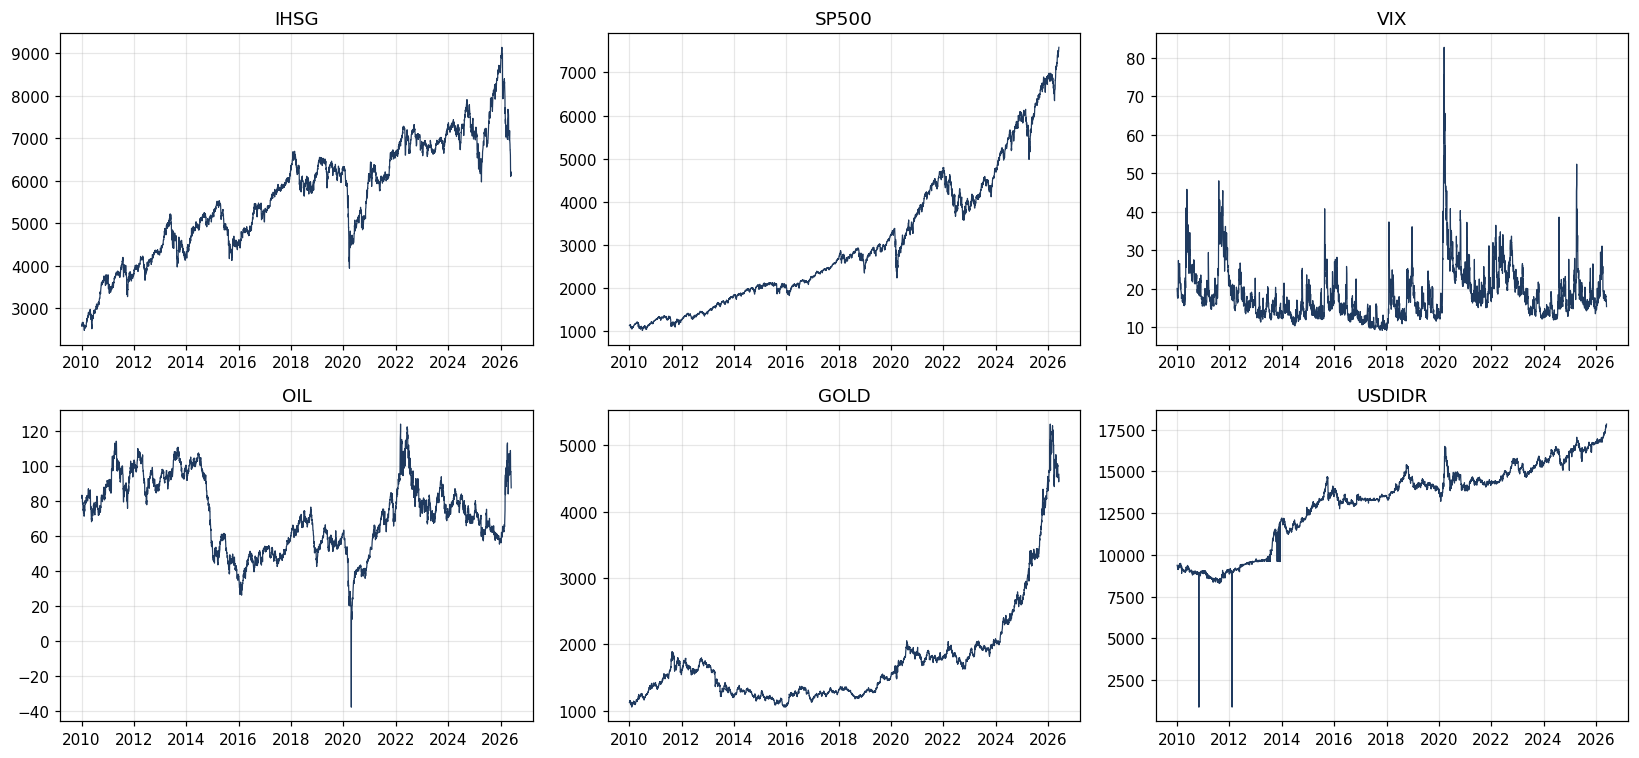

In [5]:
kolom = ['IHSG', 'SP500', 'VIX', 'OIL', 'GOLD', 'USDIDR']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, k in zip(axes.flat, kolom):
    ax.plot(df['Date'], df[k], linewidth=0.8, color='#1f3a5f')
    ax.set_title(k)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/03_grafik_variabel.png', dpi=150, bbox_inches='tight')
plt.show()

Terlihat beberapa hal yang perlu diperiksa di Unit 4: harga minyak (OIL) sempat **negatif** pada 2020, dan grafik
USD/IDR memiliki beberapa **lonjakan tajam ke bawah** yang tidak wajar.

## 4. Seberapa sering IHSG naik?

In [6]:
ihsg = df[['Date', 'IHSG']].dropna()
perubahan = ihsg['IHSG'].pct_change() * 100
perubahan = perubahan[perubahan != 0].dropna()   # abaikan hari libur BEI (nilai tidak berubah)
print(f'Hari IHSG naik  : {(perubahan > 0).mean():.1%}')
print(f'Hari IHSG turun : {(perubahan < 0).mean():.1%}')

Hari IHSG naik  : 54.2%
Hari IHSG turun : 45.8%


## 5. Variabel mana yang berhubungan dengan arah IHSG besok?
Kita hitung korelasi antara perubahan setiap variabel **hari ini** dengan perubahan IHSG **besok**. Agar adil, analisis
ini hanya memakai data 2010–2022 (data sesudahnya disimpan untuk pengujian). Korelasi Spearman dipakai karena tidak
mudah terpengaruh nilai ekstrem.

VIX      -0.236
USDIDR   -0.018
IHSG      0.002
GOLD      0.086
OIL       0.137
SP500     0.289
Name: IHSG_besok, dtype: float64


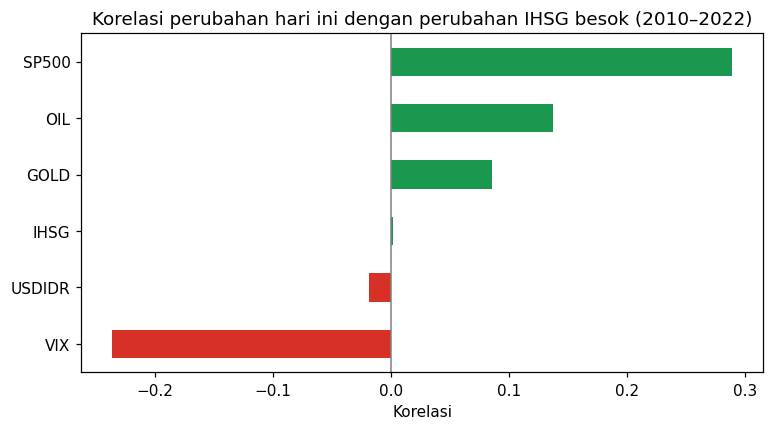

In [7]:
data = df[df['Date'] <= '2022-12-31'].dropna()
data = data[data['IHSG'].diff() != 0]            # hanya hari bursa BEI
chg = data[kolom].pct_change() * 100
chg['IHSG_besok'] = chg['IHSG'].shift(-1)
korelasi = chg.corr(method='spearman')['IHSG_besok'].drop('IHSG_besok').sort_values()
print(korelasi.round(3))

warna = ['#1a9850' if v > 0 else '#d73027' for v in korelasi]
korelasi.plot(kind='barh', color=warna, figsize=(8, 4))
plt.axvline(0, color='grey', linewidth=1)
plt.title('Korelasi perubahan hari ini dengan perubahan IHSG besok (2010–2022)')
plt.xlabel('Korelasi')
plt.savefig('../figures/03_korelasi_ihsg_besok.png', dpi=150, bbox_inches='tight')
plt.show()

## Kesimpulan
- Data berisi **4.277 hari kerja** (1 Jan 2010 – 29 Mei 2026) dengan 9 variabel numerik.
- IHSG naik pada sekitar **54%** hari bursa, jadi kelas Naik dan Turun cukup seimbang.
- **S&P 500** paling berhubungan dengan arah IHSG besok (korelasi +0,29): jika bursa Amerika naik semalam, IHSG
  cenderung naik keesokan harinya. **VIX** berhubungan terbalik (−0,24).
- Ada data yang janggal (minyak negatif, lonjakan kurs) yang diperiksa di Unit 4.